# Downstream tasks — per-task example gallery

- Per task: 4 example samples as RGB image + colored mask, with a legend of classes present in that sample
- DESIS-CDL / EO1-CDL skipped (same task as CDL, different sensor)
- H2SR skipped (no data on this system)
- Hyperview shown as regression targets, not a mask (soil P/K/Mg/pH)
- Corine shown as a flat label strip, not a spatial mask (patch-level multilabel)
- Some tasks' class names are placeholders (`code N`) — no authoritative code→name mapping found

In [1]:
from __future__ import annotations

import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import yaml
from matplotlib.patches import FancyBboxPatch

REPO = "/dss/dsshome1/08/di54zop/his-bench_dev"
sys.path.insert(0, REPO)
os.chdir(REPO)  # nbconvert runs with cwd=notebooks/ by default; data/splits/... paths are repo-root-relative

from src.datasets.bdforet_dataset import BDForetDataset
from src.datasets.bnetd_dataset import BNETDDataset
from src.datasets.cdl_dataset import CDLDataset
from src.datasets.corine_dataset import CorineDataset
from src.datasets.eurocrops_dataset import EurocropsDataset
from src.datasets.gaofen5_wuhan_dataset import Gaofen5WuhanDataset
from src.datasets.hyperview import HyperviewDataset
from src.datasets.nlcd_dataset import NLCDDataset
from src.datasets.oxhyperminerals_emit_l2a_dataset import (
    LABEL_PRODUCT_CLASS_COLORS,
    OxHyperMineralsEMITL2ADataset,
)
from src.datasets.treemap_dataset import TreeMapDataset

DATA_DIR = "/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/enmap_data_final/spectral_earth_mm_subset/downstream_tasks"

plt.rcParams.update({
    "font.family": "serif",       # falls back to default serif quietly -- see
                                    # wrong_wavelength_ablation_results.ipynb for why
                                    # "Computer Modern Roman" isn't set explicitly
    "text.usetex": False,          # no local LaTeX toolchain on this machine
    "mathtext.fontset": "cm",
    "font.size": 11,
    "figure.dpi": 110,
})

## Class-name maps & helpers

In [2]:
# Verified against official sources -- see intro markdown.
CDL_NAMES = {
    0: "Background", 1: "Corn", 2: "Cotton", 3: "Rice", 4: "Sorghum", 5: "Soybeans",
    6: "Sunflower", 45: "Sugarcane", 54: "Tomatoes", 69: "Grapes", 72: "Citrus",
    75: "Almonds", 76: "Walnuts", 204: "Pistachios", 210: "Prunes",
}
NLCD_NAMES = {
    0: "Background", 11: "Open Water", 21: "Developed, Open Space",
    22: "Developed, Low Intensity", 23: "Developed, Medium Intensity",
    24: "Developed, High Intensity", 31: "Barren Land", 41: "Deciduous Forest",
    42: "Evergreen Forest", 43: "Mixed Forest", 52: "Shrub/Scrub",
    71: "Grassland/Herbaceous", 81: "Pasture/Hay", 82: "Cultivated Crops",
    90: "Woody Wetlands", 95: "Emergent Herbaceous Wetlands",
}
NO_NAMES: dict[int, str] = {}  # placeholder -> legend falls back to "code N"


def sensor_cfg(name: str) -> dict:
    return yaml.safe_load(open(f"{REPO}/configs/sensor/{name}.yaml"))


def load_classes(task_yaml: str) -> list[int]:
    return yaml.safe_load(open(f"{REPO}/configs/data/{task_yaml}.yaml"))["classes"]


def rgb_from_image(image, rgb_indices) -> np.ndarray:
    img = image[rgb_indices].numpy().transpose(1, 2, 0)
    lo, hi = np.percentile(img, 2), np.percentile(img, 98)
    return np.clip((img - lo) / max(hi - lo, 1e-6), 0, 1)


def quartile_indices(n: int, k: int = 4) -> list[int]:
    """4 sample indices spread through the split (0%, 25%, 50%, 75%), not just index 0."""
    return sorted(set(min(n - 1, int(n * f)) for f in np.linspace(0, 0.75, k)))[:k]


def draw_legend_block(ax, items: list[tuple[str, np.ndarray]], ncols: int = 3) -> None:
    """A single light-gray rounded box containing a grid of color swatches + labels."""
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    if not items:
        ax.text(0.5, 0.5, "(no foreground classes in this sample)", ha="center", va="center",
                 fontsize=10, color="#777777")
        return
    nrows = max(1, int(np.ceil(len(items) / ncols)))
    box = FancyBboxPatch((0.01, 0.02), 0.98, 0.96, boxstyle="round,pad=0.01,rounding_size=0.03",
                          linewidth=0.8, edgecolor="#c9c8c2", facecolor="#f4f4f2", zorder=1,
                          transform=ax.transAxes)
    ax.add_patch(box)
    cell_w, cell_h = 0.98 / ncols, 0.92 / nrows
    for i, (name, color) in enumerate(items):
        r, c = divmod(i, ncols)
        x0, y0 = 0.03 + c * cell_w, 0.96 - (r + 1) * cell_h
        sw_w, sw_h = 0.05, cell_h * 0.5
        ax.add_patch(plt.Rectangle((x0, y0 + (cell_h - sw_h) / 2), sw_w, sw_h,
                                    facecolor=color, edgecolor="none", zorder=2))
        ax.text(x0 + sw_w + 0.015, y0 + cell_h / 2, name, va="center", ha="left",
                fontsize=10, zorder=2)


def base_figure(img, mask_colored, legend_items, title: str):
    fig = plt.figure(figsize=(7, 6.0))
    gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.2], hspace=0.08, wspace=0.05,
                           top=0.90, bottom=0.03, left=0.02, right=0.98)
    ax_img, ax_mask = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
    ax_legend = fig.add_subplot(gs[1, :])
    ax_img.imshow(img); ax_img.axis("off")
    if mask_colored is not None:
        ax_mask.imshow(mask_colored); ax_mask.axis("off")
    else:
        ax_mask.axis("off")
    draw_legend_block(ax_legend, legend_items)
    fig.suptitle(title, y=0.97, fontsize=12)
    return fig


def run_base_task(label: str, cls, root_suffix: str, sensor: str, product: str, task_yaml: str, name_map: dict):
    """Shared path for every BaseSegmentationDataset-family task (CDL, BDForet,
    BNETD, NLCD, TreeMap, EuroCrops)."""
    ds = cls(root=f"{DATA_DIR}/{root_suffix}", sensor_config=sensor_cfg(sensor), product=product,
             split="train", split_root="data/splits", classes=load_classes(task_yaml))
    for i, idx in enumerate(quartile_indices(len(ds))):
        sample = ds[idx]
        img = rgb_from_image(sample["image"], ds.rgb_indices)
        mask = sample["mask"].squeeze(0)
        colored = ds.ordinal_cmap[np.clip(mask.numpy(), 0, ds.ordinal_cmap.shape[0] - 1)].numpy()
        items = []
        for o in sorted(int(v) for v in mask.unique().tolist()):
            if o == ds.background_class_ordinal:
                continue
            raw_val = ds.foreground_classes_raw[o]
            items.append((name_map.get(raw_val, f"code {raw_val}"), ds.ordinal_cmap[o].numpy() / 255.0))
        fig = base_figure(img, colored, items, f"{label} -- example {i + 1} (idx={idx})")
        plt.show()
    print(f"{label}: {len(ds)} samples")

## CDL

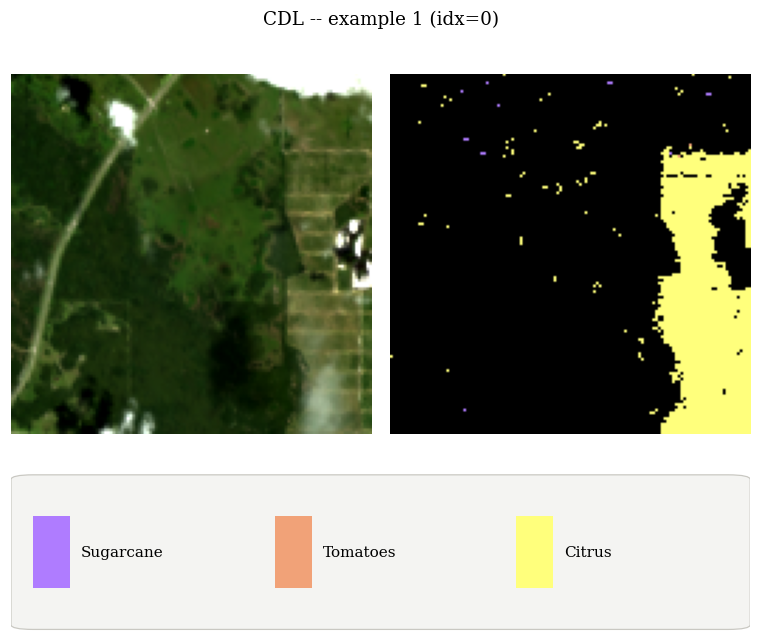

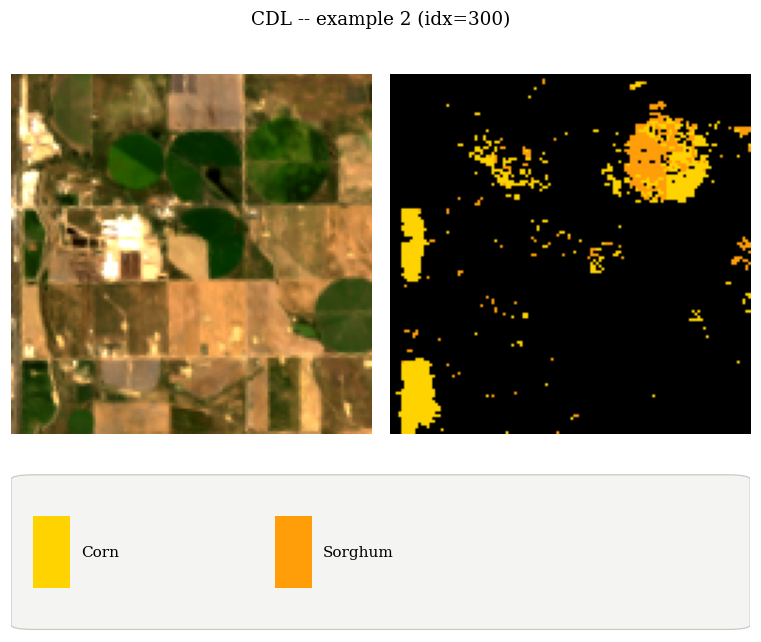

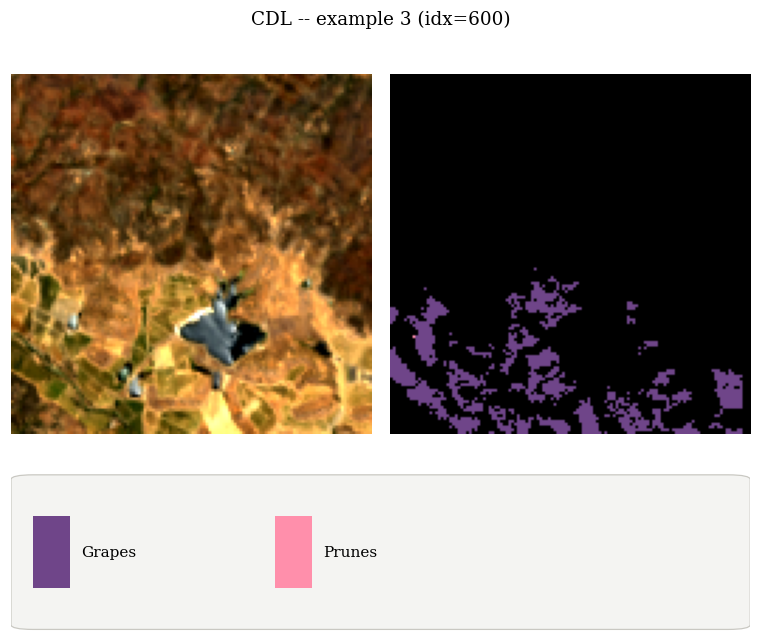

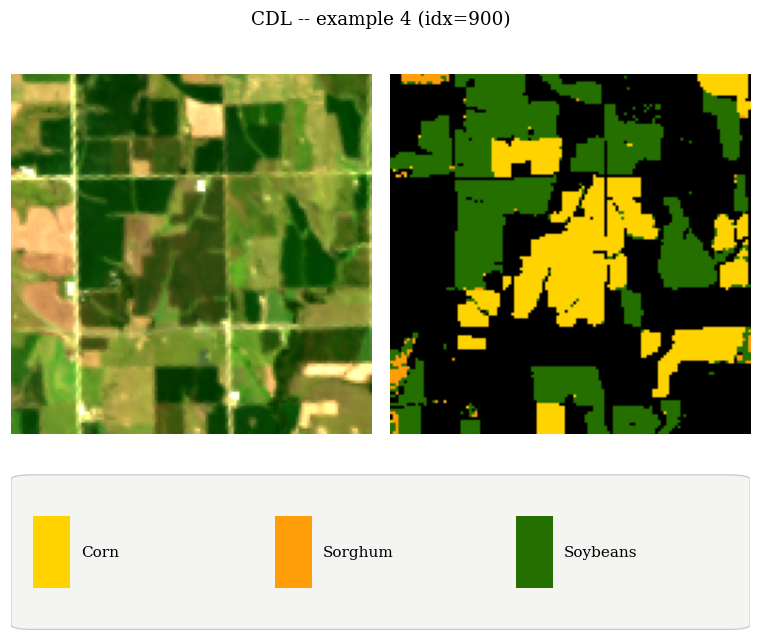

CDL: 1200 samples


In [3]:
run_base_task("CDL", CDLDataset, "cdl", "enmap", "cdl", "cdl", CDL_NAMES)

## BDForêt

*Class names are placeholders (`code N`) -- see intro.*

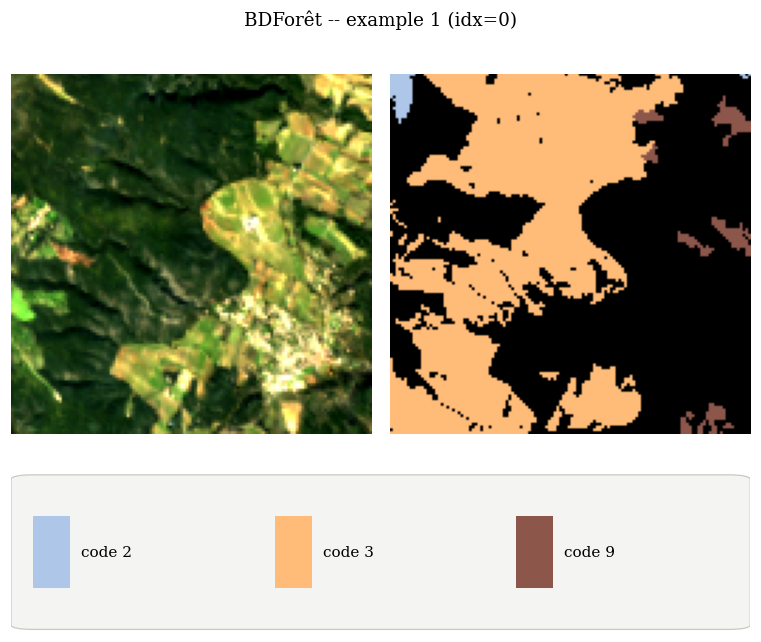

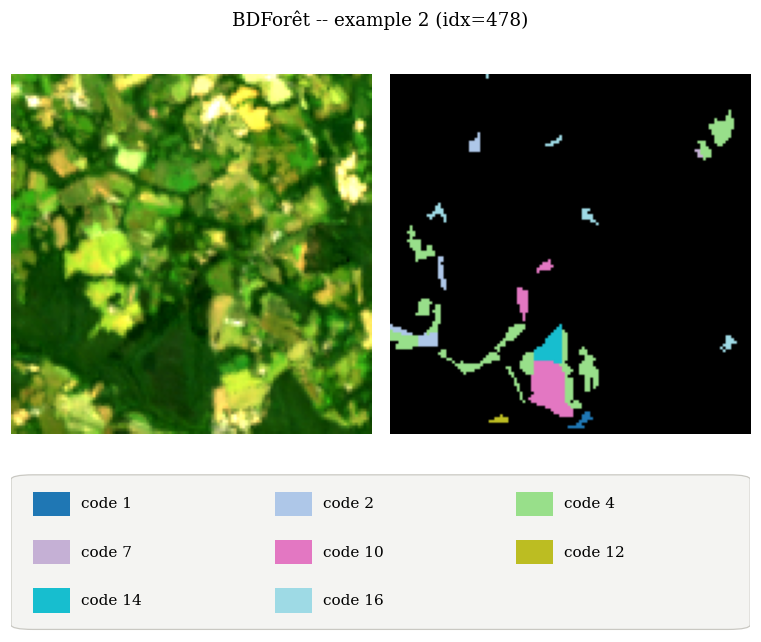

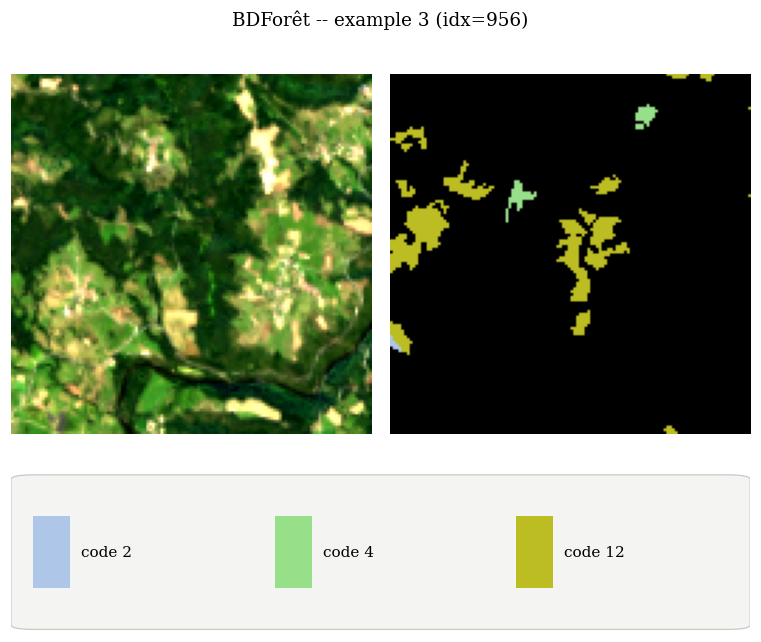

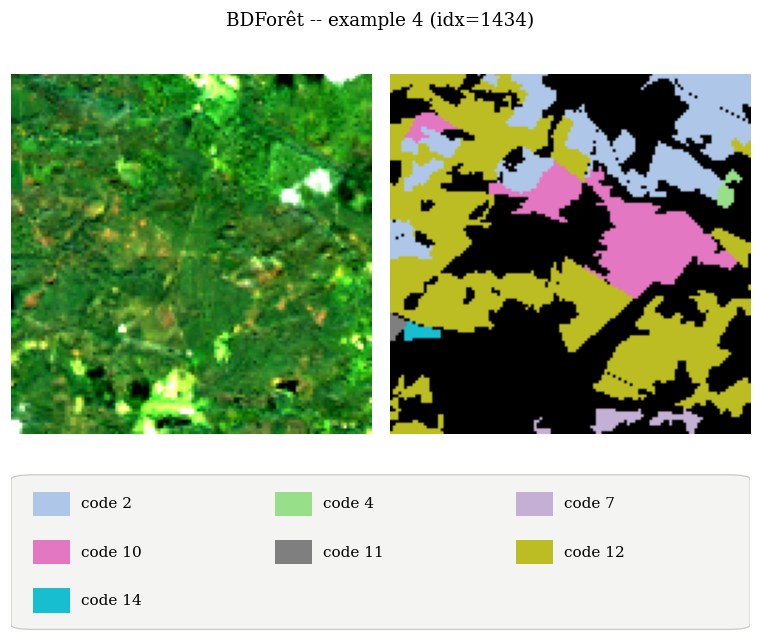

BDForêt: 1912 samples


In [4]:
run_base_task("BDForêt", BDForetDataset, "bdforet", "enmap", "bdforet", "bdforet", NO_NAMES)

## BNETD

*Class names are placeholders (`code N`) -- see intro.*

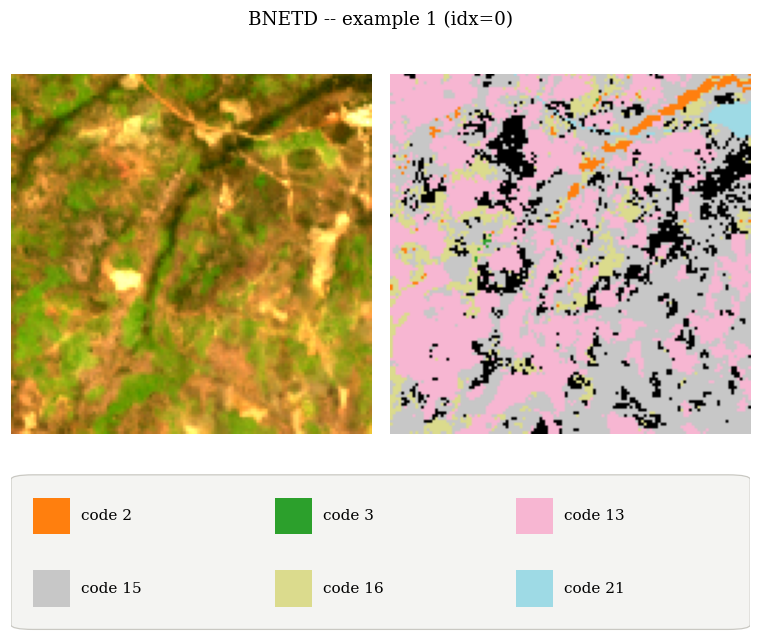

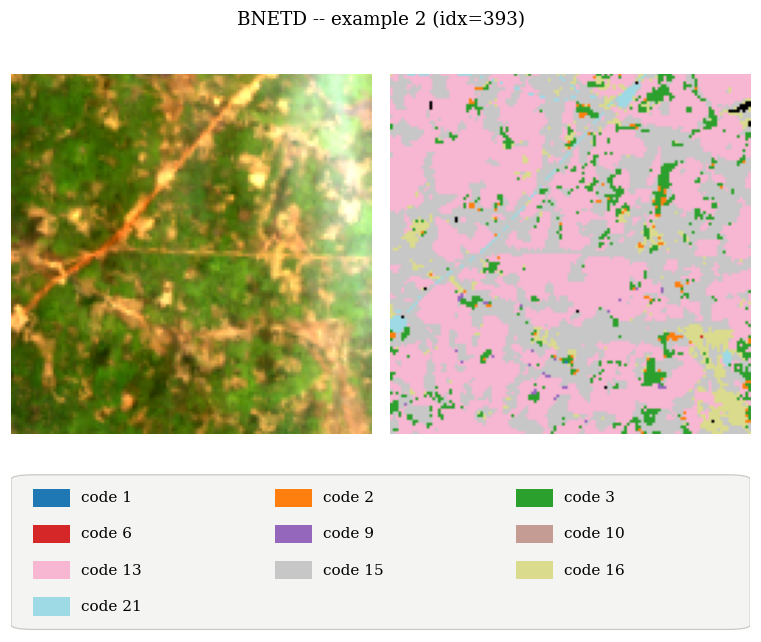

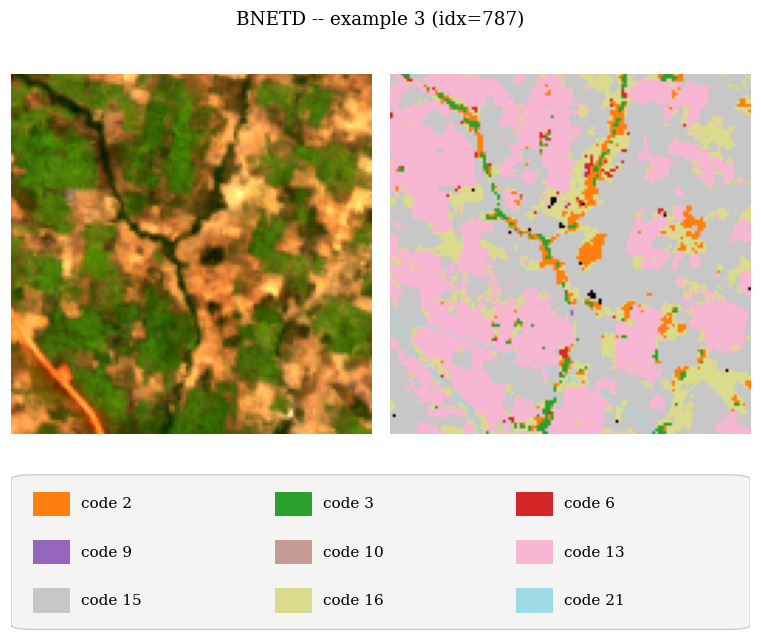

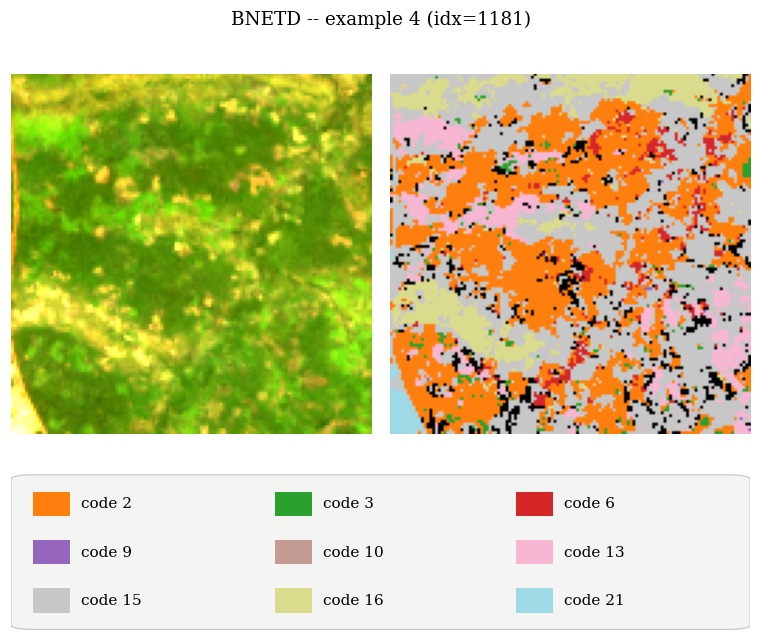

BNETD: 1575 samples


In [5]:
run_base_task("BNETD", BNETDDataset, "bnetd", "enmap", "bnetd", "bnetd", NO_NAMES)

## NLCD

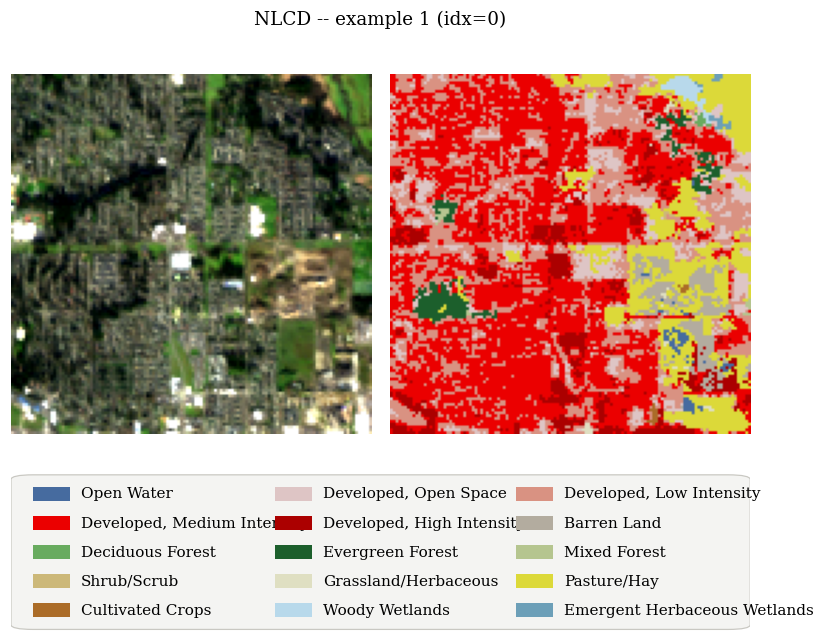

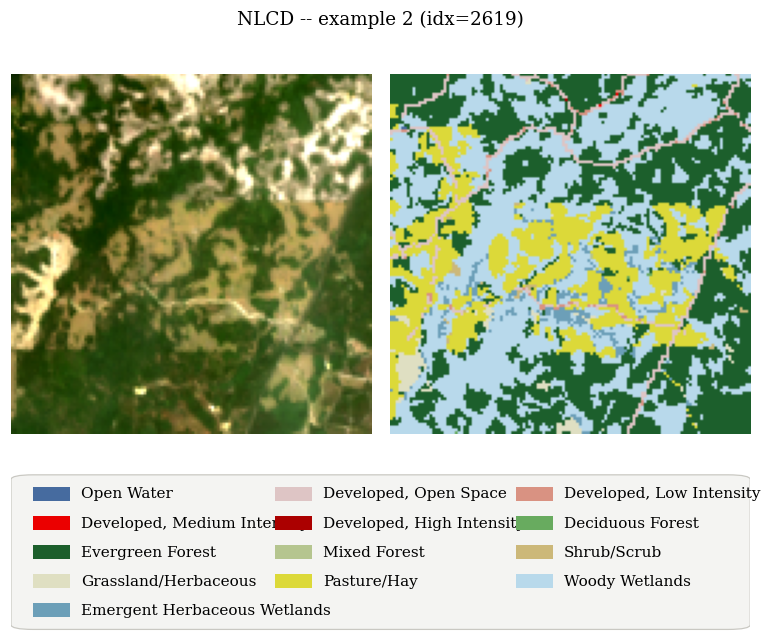

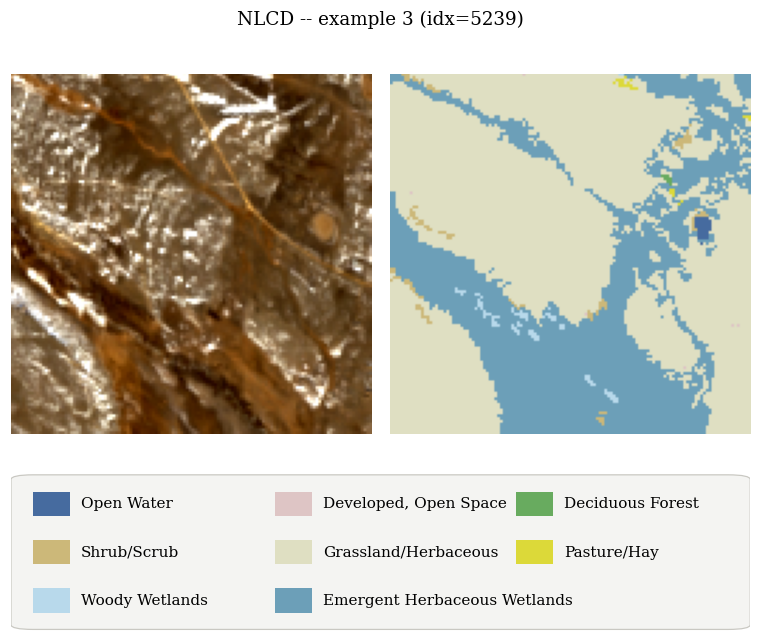

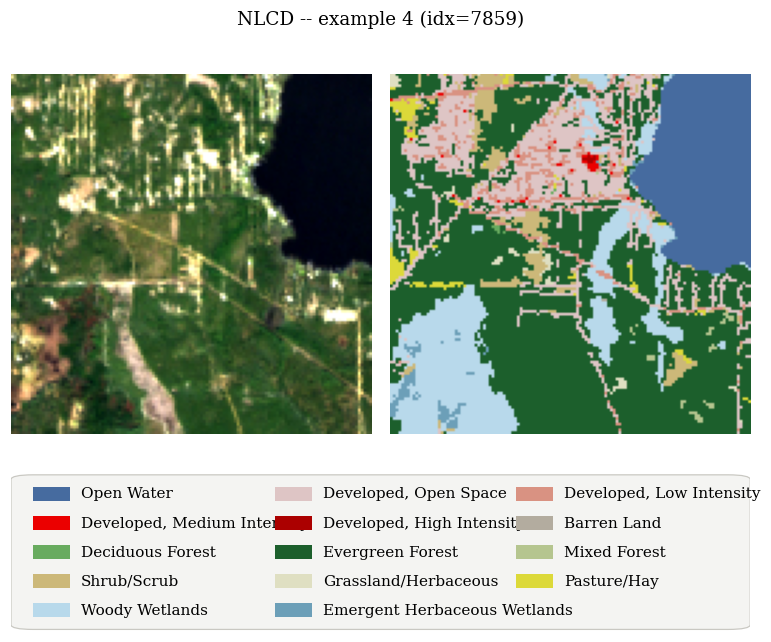

NLCD: 10479 samples


In [6]:
run_base_task("NLCD", NLCDDataset, "nlcd", "enmap", "nlcd", "nlcd", NLCD_NAMES)

## TreeMap

*Class names are placeholders (`code N`) -- see intro.*

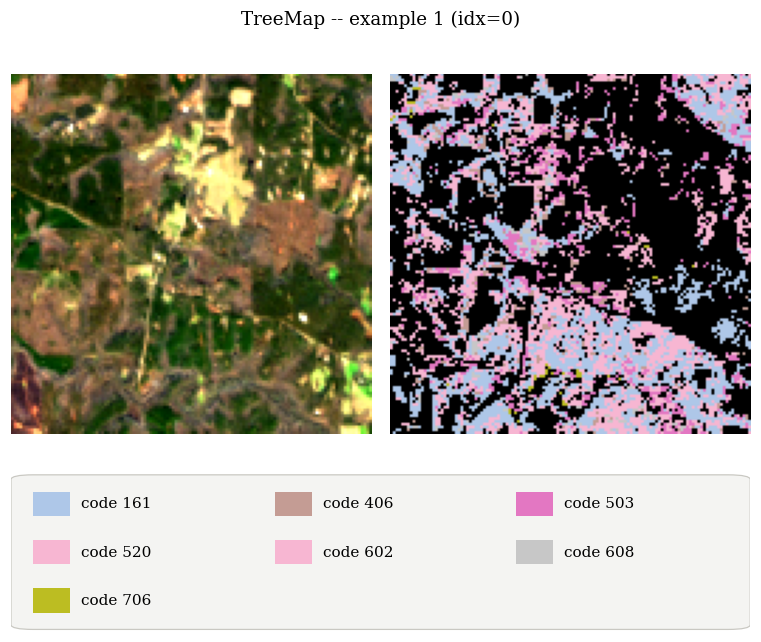

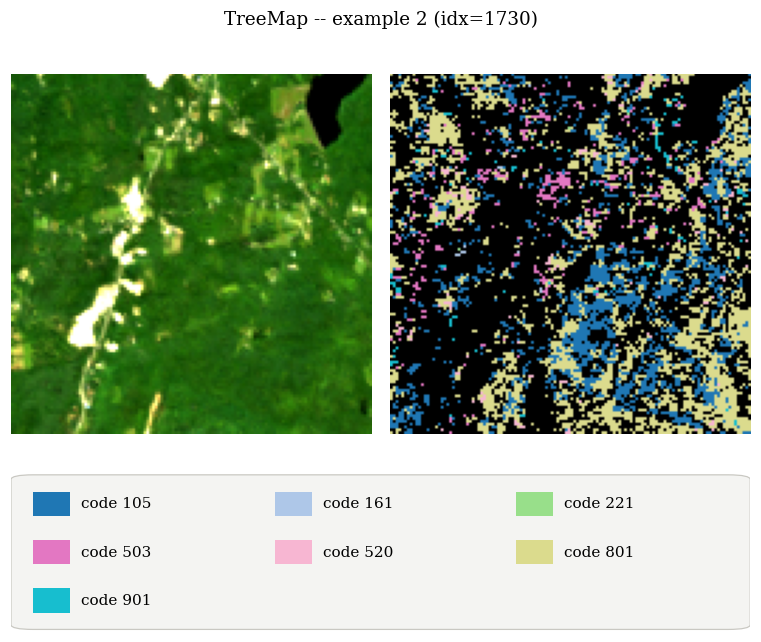

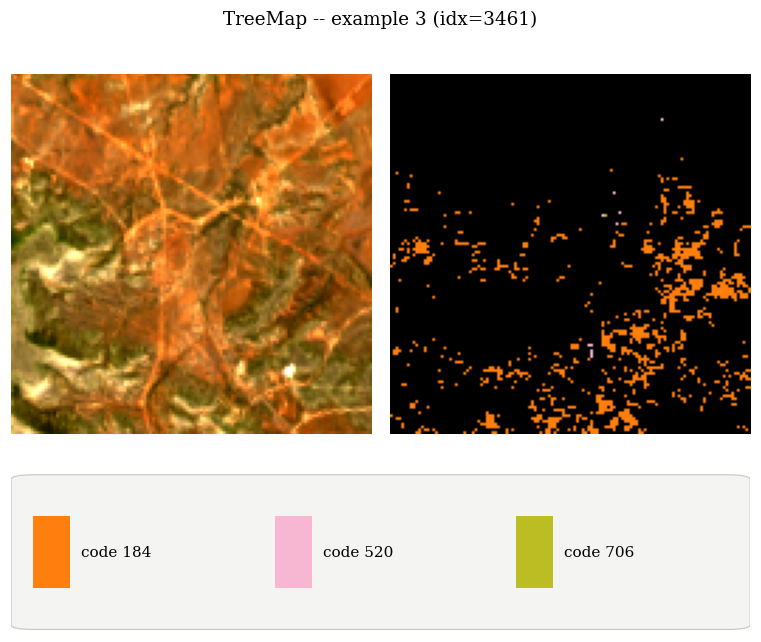

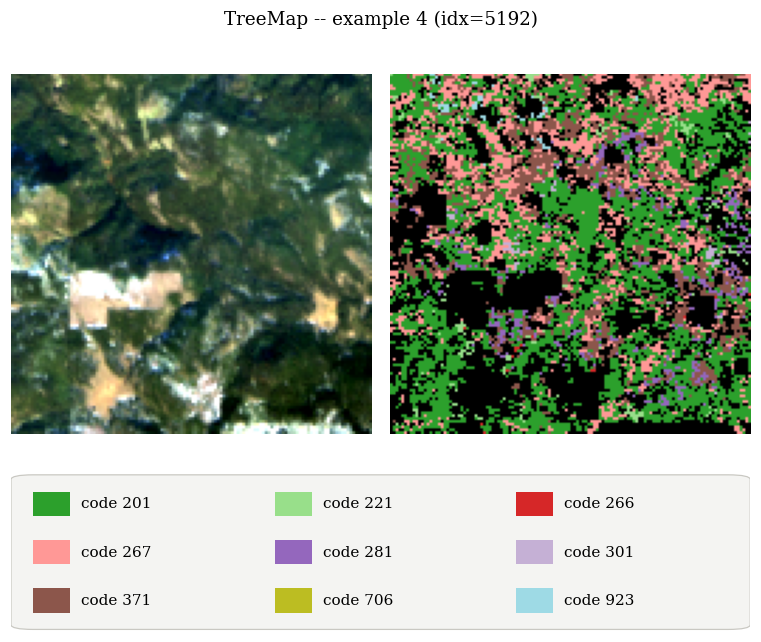

TreeMap: 6923 samples


In [7]:
run_base_task("TreeMap", TreeMapDataset, "treemap", "enmap", "treemap", "treemap", NO_NAMES)

## EuroCrops

*Class names are placeholders (`code N`) -- see intro.*

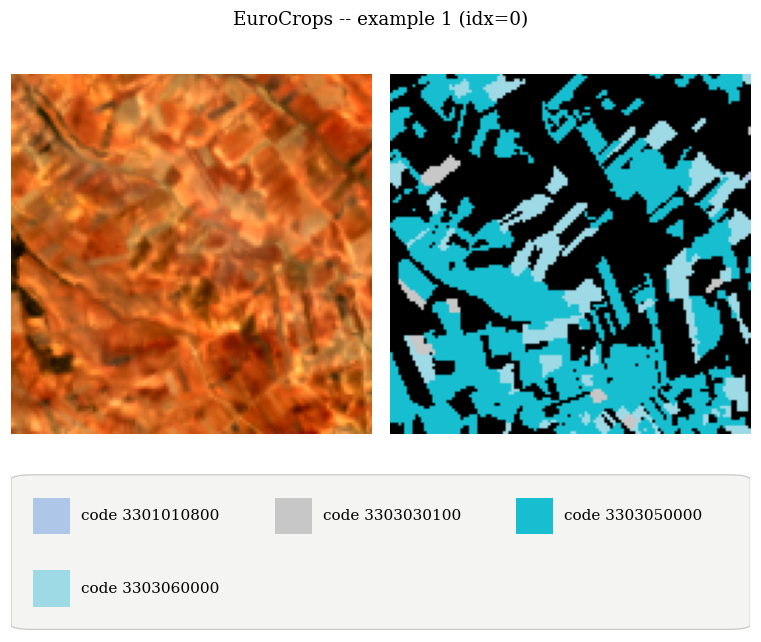

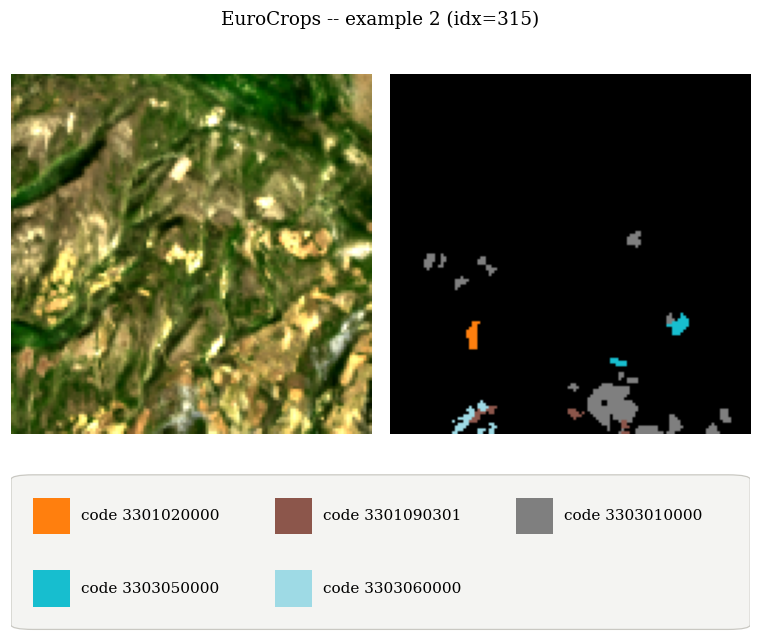

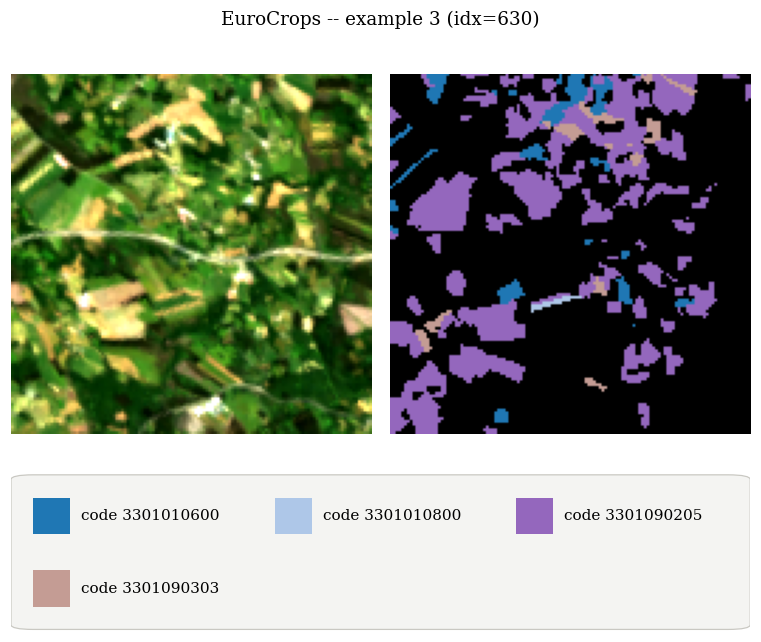

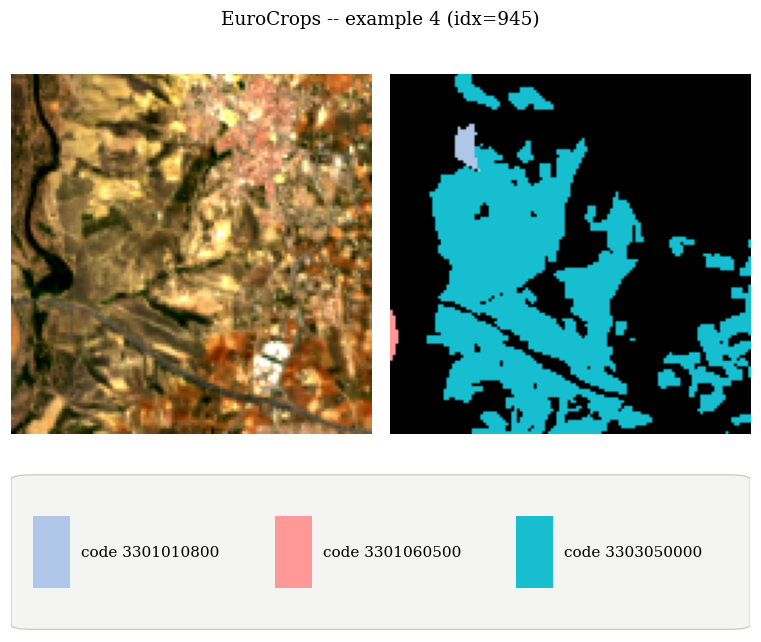

EuroCrops: 1260 samples


In [8]:
run_base_task("EuroCrops", EurocropsDataset, "eurocrops", "enmap", "eurocrops", "eurocrops", NO_NAMES)

## Gaofen5-Wuhan

/dss/dsshome1/08/di54zop/micromamba/envs/hsi-bench/lib/python3.11/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


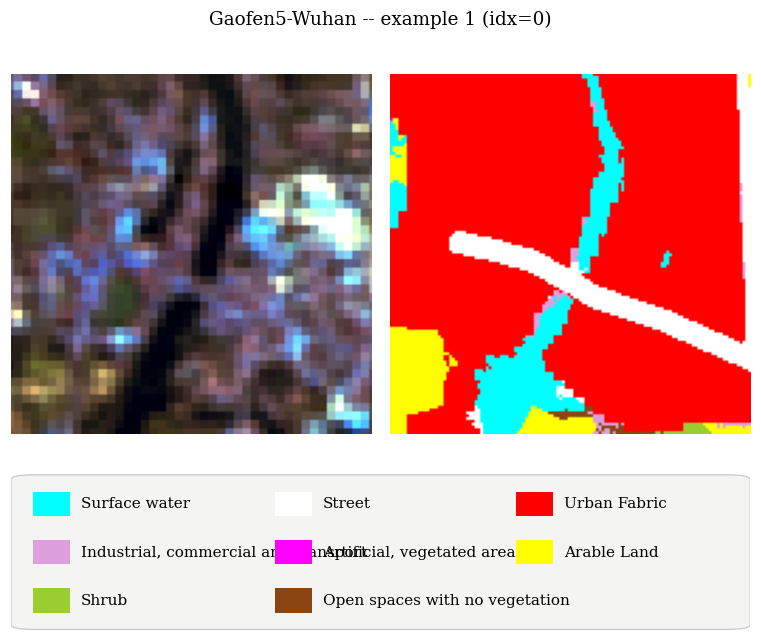

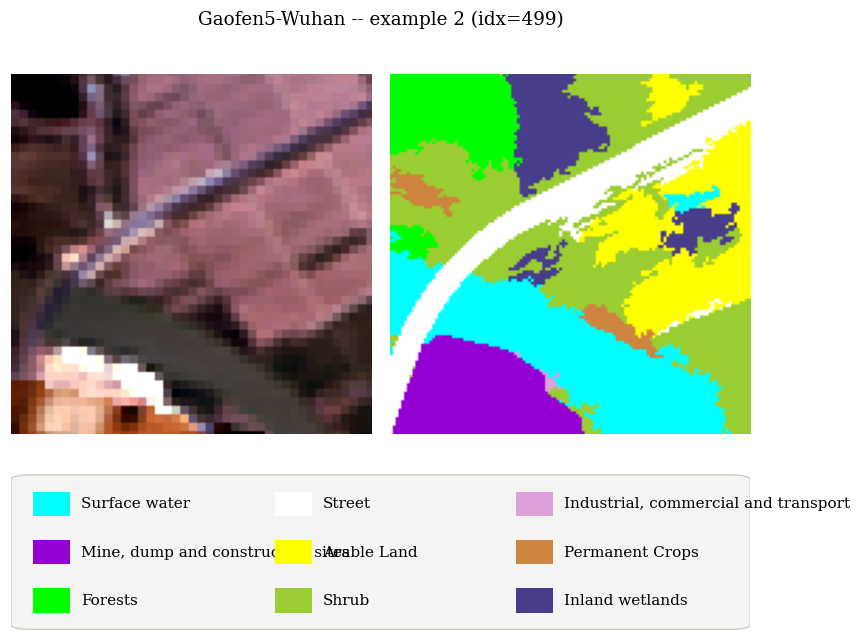

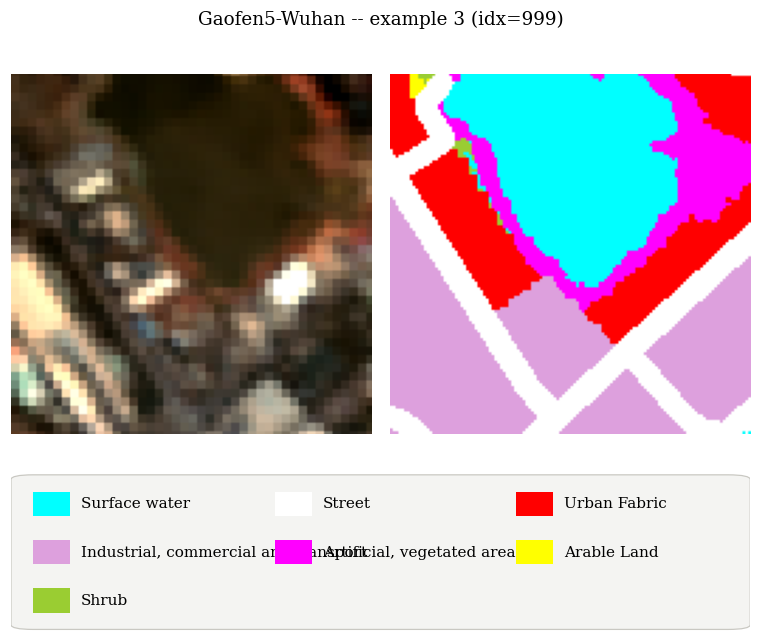

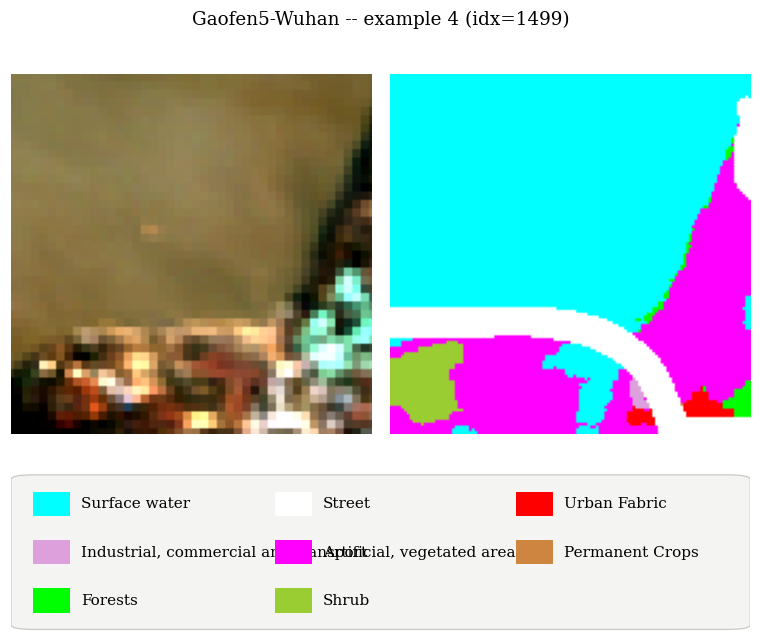

Gaofen5-Wuhan: 1999 samples


In [9]:
ds = Gaofen5WuhanDataset(root="/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/gaofen5_dataset/wuhan_highres_128",
                          sensor_config=sensor_cfg("gaofen5"), product="gaofen5_wuhan",
                          split="train", split_root="data/splits", classes=load_classes("gaofen5_wuhan"))
cmap = ds._mapped_cmap()
for i, idx in enumerate(quartile_indices(len(ds))):
    sample = ds[idx]
    img = rgb_from_image(sample["image"], ds.rgb_indices)
    mask = sample["mask"]
    colored = cmap[mask.numpy()]
    items = [(ds.class_names.get(o, f"code {o}"), np.asarray(cmap[o]) / 255.0)
             for o in sorted(int(v) for v in mask.unique().tolist()) if o != ds.ignore_index]
    fig = base_figure(img, colored, items, f"Gaofen5-Wuhan -- example {i + 1} (idx={idx})")
    plt.show()
print(f"Gaofen5-Wuhan: {len(ds)} samples")

## OxHyp

Multilabel mineral segmentation -- a pixel can be e.g. both Goethite and Hematite
simultaneously. Legend lists only classes with at least one positive pixel in that sample.

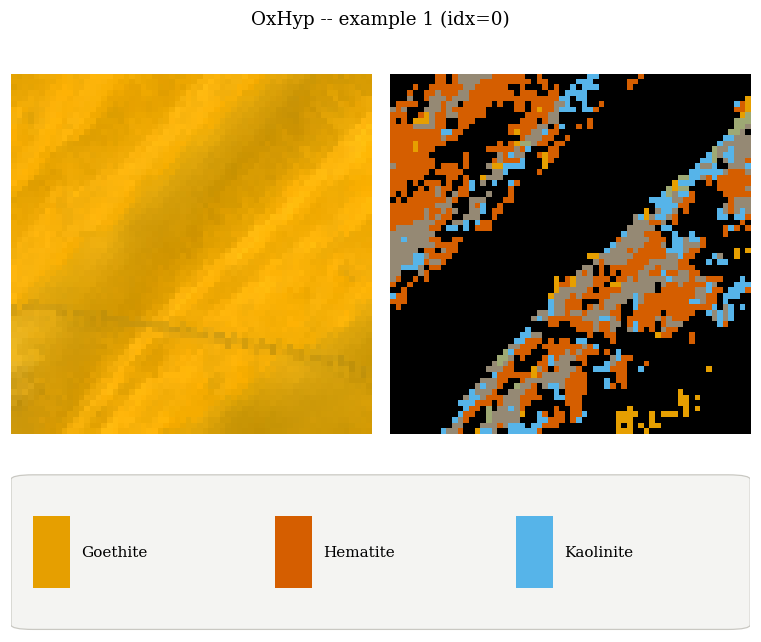

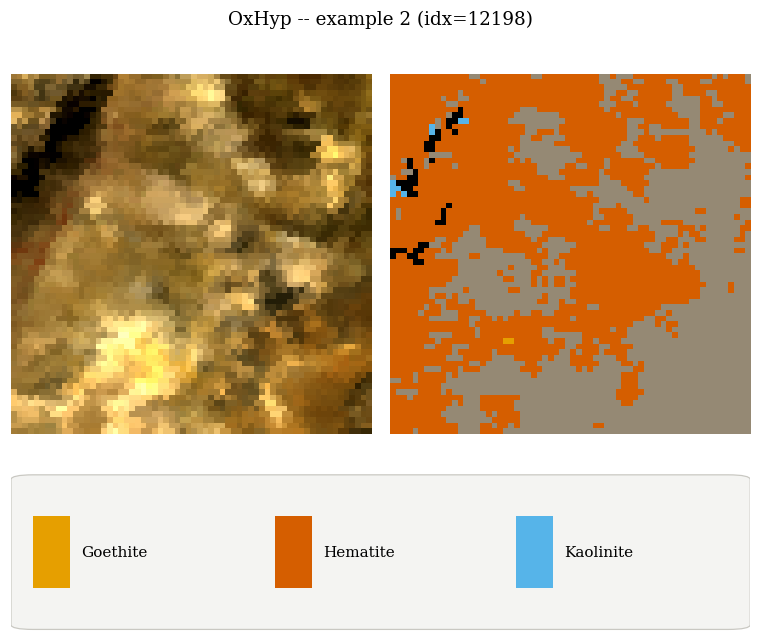

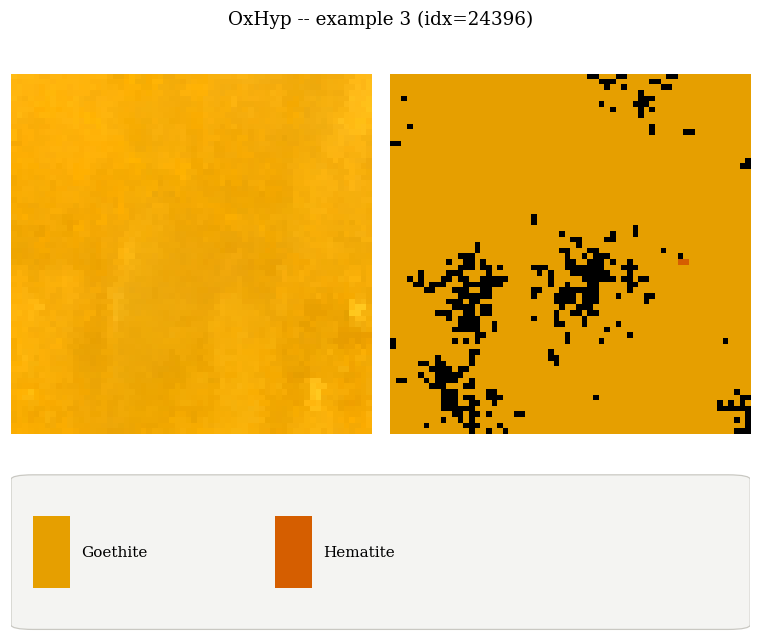

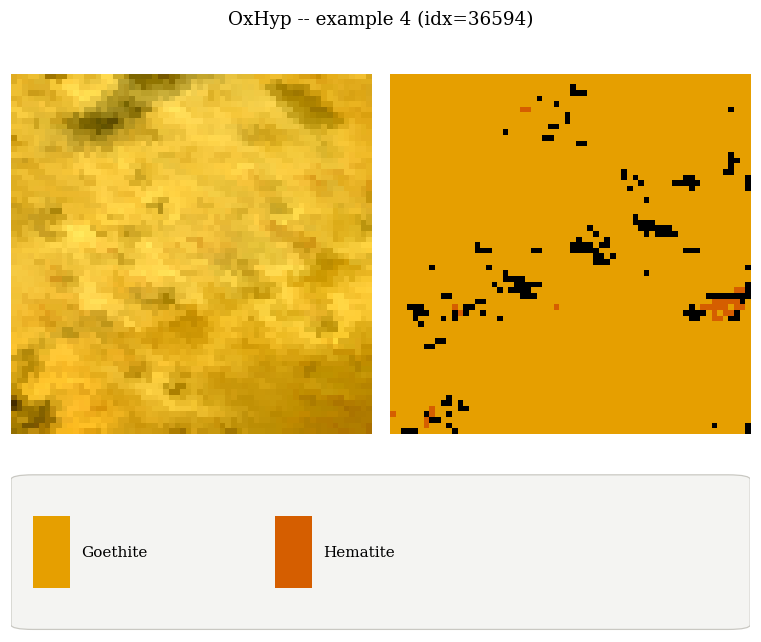

OxHyp: 48792 samples


In [10]:
ds = OxHyperMineralsEMITL2ADataset(
    root="/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/oxhyperminerals_emit_l2a_author64_valid99",
    split="train", sensor_config=sensor_cfg("emit"), product="oxhyperminerals_emit_l2a",
    label_product="minerals3ghk", classes=[0, 1, 2], split_root="data/splits",
)
for i, idx in enumerate(quartile_indices(len(ds))):
    sample = ds[idx]
    img = rgb_from_image(sample["image"], ds.rgb_indices)
    colored = ds._render_multilabel(sample["mask"].numpy())
    binary = sample["mask"].numpy() > 0.5
    items = [(ds.class_names[j], np.asarray(LABEL_PRODUCT_CLASS_COLORS[ds.label_product][j]) / 255.0)
             for j in range(len(ds.classes)) if binary[j].any()]
    fig = base_figure(img, colored, items, f"OxHyp -- example {i + 1} (idx={idx})")
    plt.show()
print(f"OxHyp: {len(ds)} samples")

## Corine

Patch-level multilabel scene classification, not per-pixel segmentation -- the
"mask" panel is a flat color strip of the active scene labels in this patch, not a
spatial mask (Corine has no official per-pixel colormap wired into this codebase).

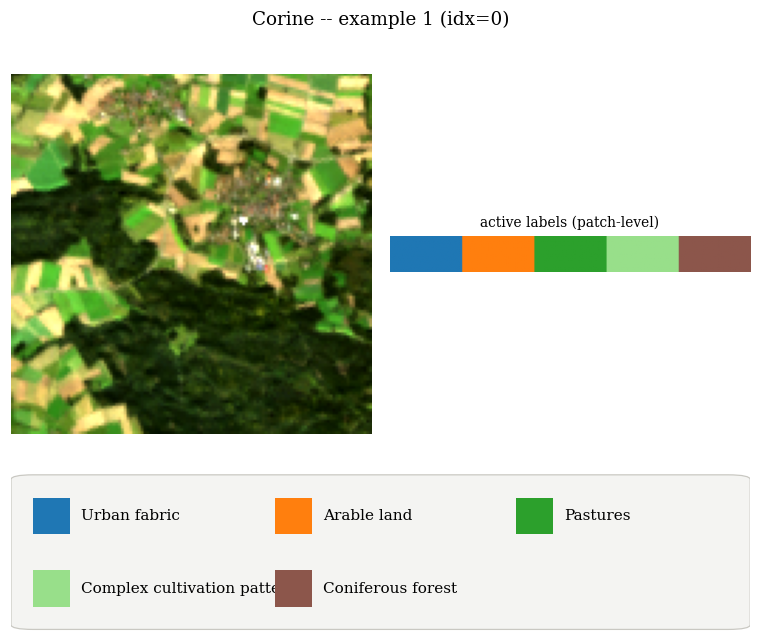

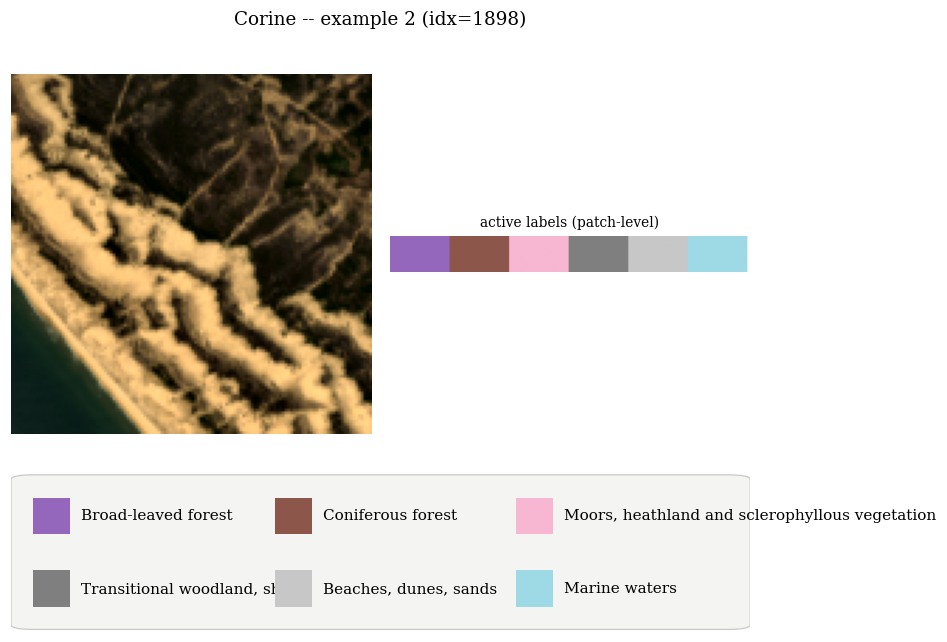

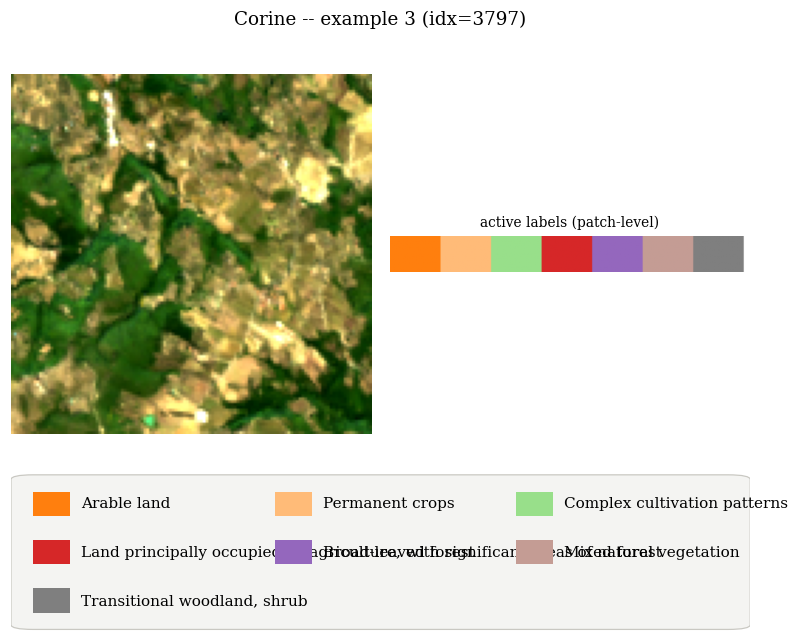

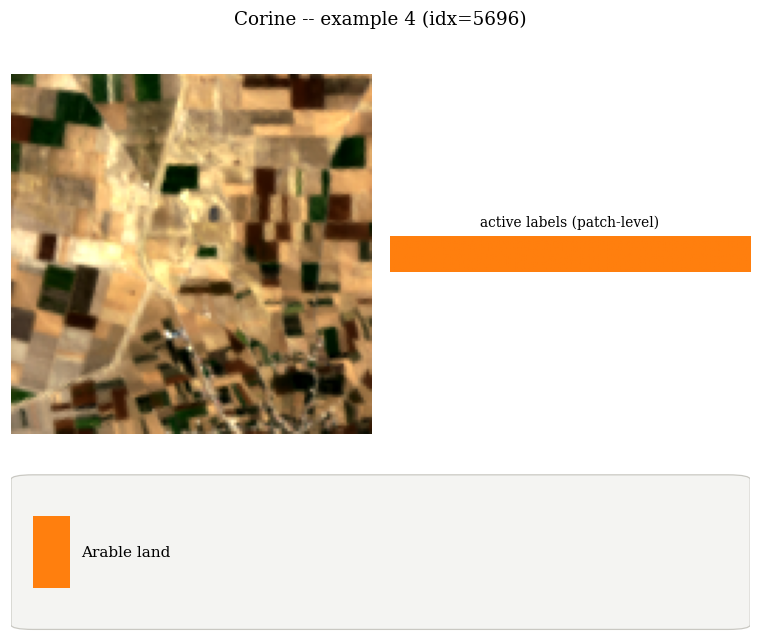

Corine: 7595 samples


In [11]:
ds = CorineDataset(root=f"{DATA_DIR}/corine", sensor_config=sensor_cfg("enmap"), product="corine",
                    split="train", num_classes=19)
cmap19 = plt.get_cmap("tab20", 19)
for i, idx in enumerate(quartile_indices(len(ds))):
    sample = ds[idx]
    img = rgb_from_image(sample["image"], ds.rgb_indices)
    active = ds._onehot_labels_to_names(sample["label"])
    active_idx = [ds.class_names.index(n) for n in active]
    items = [(name, cmap19(j % 19)[:3]) for name, j in zip(active, active_idx)]

    strip = np.ones((20, 200, 3))
    if items:
        seg = 200 // len(items)
        for k, (_, color) in enumerate(items):
            strip[:, k * seg:(k + 1) * seg] = color

    fig = plt.figure(figsize=(7, 6.0))
    gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.2], hspace=0.08, wspace=0.05,
                           top=0.90, bottom=0.03, left=0.02, right=0.98)
    ax_img, ax_mask = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
    ax_legend = fig.add_subplot(gs[1, :])
    ax_img.imshow(img); ax_img.axis("off")
    ax_mask.imshow(strip); ax_mask.axis("off")
    ax_mask.set_title("active labels (patch-level)", fontsize=9)
    draw_legend_block(ax_legend, items)
    fig.suptitle(f"Corine -- example {i + 1} (idx={idx})", y=0.97, fontsize=12)
    plt.show()
print(f"Corine: {len(ds)} samples")

## Hyperview

Regression (soil P/K/Mg/pH), not classification -- no class legend applies. No native
`sensor_config`/`rgb_indices` for this resampled 150-band product, so the RGB bands used
here are a rough proportional analogue of EnMAP's own `rgb_indices`, not an authoritative
band choice.

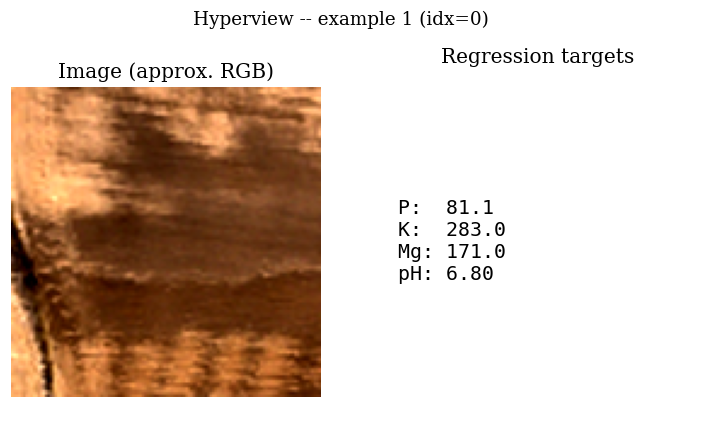

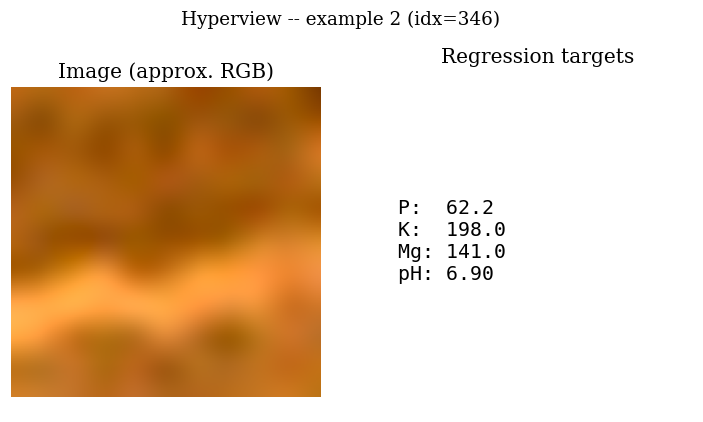

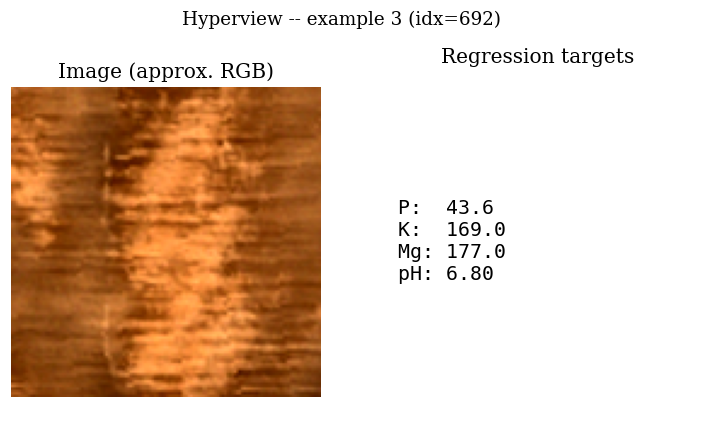

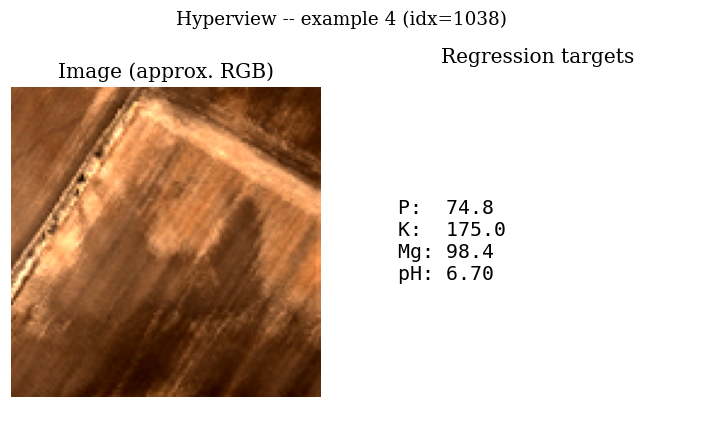

Hyperview: 1385 samples


In [12]:
HyperviewDataset.gt_file_path = "/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/enmap_data_final/hyperview_new/{}.csv"
ds = HyperviewDataset(root="/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/enmap_data_final/hyperview_new",
                       data_dir="images", split="train", num_bands=150, patch_size=128)
rgb = [32, 21, 7]
for i, idx in enumerate(quartile_indices(len(ds))):
    sample = ds[idx]
    img = rgb_from_image(sample["image"], rgb)
    label = sample["label"].numpy()
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title("Image (approx. RGB)")
    axes[1].axis("off")
    axes[1].text(0.05, 0.5, f"P:  {label[0]:.1f}\nK:  {label[1]:.1f}\nMg: {label[2]:.1f}\npH: {label[3]:.2f}",
                  fontsize=13, family="monospace", va="center")
    axes[1].set_title("Regression targets")
    fig.suptitle(f"Hyperview -- example {i + 1} (idx={idx})", y=1.02, fontsize=12)
    plt.show()
print(f"Hyperview: {len(ds)} samples")